<a href="https://colab.research.google.com/github/lgumieniak/NLP-Deep-Learning/blob/main/NLP_AppliFinal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install langdetect
!pip install streamlit
!pip install pyngrok

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 19.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993222 sha256=84a299be80ebbc26c69a21e00db58f339773f10adc45319a4b0f7aa322261324
  Stored in directory: /root/.cache/pip/wheels/0a/f2/b2/e5ca405801e05eb7c8ed5b3b4bcf1fcabcd6272c167640072e
Successfully built langdetect
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 81.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 108.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 7.9 MB/s eta 0:00:00


In [ ]:
# Import des bibliothèques nécessaires
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, Concatenate, Flatten, Lambda, Dot
from tensorflow.keras import backend as K
from transformers import BertTokenizer, TFBertModel
import tensorflow as tf
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import nltk
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import pickle
from langdetect import detect
from transformers import pipeline
import streamlit as st
from pyngrok import ngrok
import os
import time
from nltk.util import ngrams
import string
import re
from collections import Counter
from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
import seaborn as sns
from torch.utils.tensorboard import SummaryWriter
from datetime import datetime

## Import des données

In [ ]:
# Importation du fichier Excel
try:
    df_train = pd.read_excel('df_train.xlsx')
    print("Fichier chargé avec succès")
    print("Dimensions du dataset :", df_train.shape)
except FileNotFoundError:
    print("Erreur : Le fichier 'df_train.xlsx' n'a pas été trouvé dans le répertoire courant")
except Exception as e:
    print("Une erreur s'est produite lors du chargement du fichier :", str(e))

# Afficher les premières lignes pour vérification
print("\nAperçu des données :")
print(df_train.head(10))

Fichier chargé avec succès
Dimensions du dataset : (24103, 9)

Aperçu des données :
   note             auteur                                               avis  \
0     4     croco47-108902  nouvelle adhérente et ayant été en contact ave...   
1     1          dt-117016  Service téléphonique lamentable, impossibilité...   
2     5   william-g-130367  Je suis très satisfait de l'ensemble des prest...   
3     4  gilberte-c-138206  Je suis satisfaite le prix me convient très bi...   
4     4         mica-72266  ..l.... .  Nickel pour l instant,  pas de  sin...   
5     1     lolita83-86385  Toujours pas de réponses aux mails envoyés pas...   
6     1     victime-122365  Attention !!! Cette assurance n'indemnise pas ...   
7     1    piloux13-115780  Ils on plus voulu m'assurer après des années s...   
8     3   tutubalci-105022  Je suis entièrement satisfaite de l'accueil té...   
9     5      shanty-117872  Je remercie Saliha qui, avec beaucoup de genti...   

              assureur  

## Nettoyage et analyse

In [ ]:
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


True

In [ ]:
def find_common_ngrams(texts, n, min_frequency=10):
    """
    Trouve les n-grammes les plus fréquents dans un corpus
    """
    all_ngrams = []
    for text in texts:
        if pd.isna(text):
            continue
        words = nltk.word_tokenize(text.lower())
        all_ngrams.extend([' '.join(ng) for ng in ngrams(words, n)])

    # Compte les occurrences
    ngram_counts = Counter(all_ngrams)

    # Retourne les n-grammes fréquents
    return {ng: count for ng, count in ngram_counts.items()
            if count >= min_frequency}

# Trouver les bigrammes et trigrammes fréquents
print("Analyse des n-grammes fréquents...")
bigrammes_fr = find_common_ngrams(df_train['avis'].dropna(), 2)
trigrammes_fr = find_common_ngrams(df_train['avis'].dropna(), 3)
bigrammes_en = find_common_ngrams(df_train['avis_en'].dropna(), 2)
trigrammes_en = find_common_ngrams(df_train['avis_en'].dropna(), 3)

# Afficher les n-grammes les plus fréquents
print("\nBigrammes français les plus fréquents :")
print(dict(sorted(bigrammes_fr.items(), key=lambda x: x[1], reverse=True)[:10]))

print("\nBigrammes anglais les plus fréquents :")
print(dict(sorted(bigrammes_en.items(), key=lambda x: x[1], reverse=True)[:10]))

print("\nTrigrammes français les plus fréquents :")
print(dict(sorted(trigrammes_fr.items(), key=lambda x: x[1], reverse=True)[:10]))

print("\nTrigrammes anglais les plus fréquents :")
print(dict(sorted(trigrammes_en.items(), key=lambda x: x[1], reverse=True)[:10]))

Analyse des n-grammes fréquents...

Bigrammes français les plus fréquents :
{'! !': 9689, 'je suis': 8147, 'de la': 5171, '. je': 4959, ', je': 4162, 'que je': 3552, "' a": 2999, 'je ne': 2953, 'à la': 2534, 'de mon': 2531}

Bigrammes anglais les plus fréquents :
{'! !': 9386, 'i am': 9269, '. i': 8043, 'of the': 7181, ', i': 7168, 'i have': 5692, 'on the': 5145, 'with the': 5030, 'it is': 4642, 'satisfied with': 4206}

Trigrammes français les plus fréquents :
{'! ! !': 5721, 'je suis satisfait': 2030, "m ' a": 1801, 'satisfait du service': 1135, 'suis satisfait du': 1033, 'prise en charge': 1009, '? ? ?': 987, "n ' a": 972, 'il y a': 955, 'je suis très': 892}

Trigrammes anglais les plus fréquents :
{'! ! !': 5530, 'satisfied with the': 3031, 'i am satisfied': 2815, 'am satisfied with': 2345, 'on the phone': 1431, 'with the service': 1378, 'i have been': 1291, 'i do not': 1255, 'i am very': 1037, ', i am': 974}


In [ ]:
# Création des listes de stopwords
stop_words_fr = set(stopwords.words('french'))
stop_words_en = set(stopwords.words('english'))

def is_french(text):
    """
    Détecte si un texte est en français en utilisant langdetect
    Args:
        text: texte à analyser
    Returns:
        bool: True si le texte est en français, False sinon
    """
    try:
        return detect(text) == 'fr'
    except:
        return False

def clean_text(text, is_french=True):
    """
    Nettoie le texte en enlevant la ponctuation, les stopwords et les caractères numériques
    Args:
        text: texte à nettoyer
        is_french: True si le texte est en français, False si en anglais
    """
    if pd.isna(text):
        return text

    # Conversion en minuscules
    text = text.lower()

    # Suppression des caractères numériques
    text = re.sub(r'\d+', ' ', text)  # Remplace tous les chiffres par des espaces

    # Suppression de la ponctuation
    text = re.sub(r'[^\w\s]', ' ', text)  # Remplace tous les caractères non-alphanumériques par des espaces

    # Nettoyage des espaces multiples
    text = re.sub(r'\s+', ' ', text)  # Remplace les espaces multiples par un seul espace

    # Tokenization
    words = nltk.word_tokenize(text)

    # Suppression des stopwords selon la langue
    if is_french:
        words = [word for word in words if word not in stop_words_fr]
    else:
        words = [word for word in words if word not in stop_words_en]

    # Reconstruction du texte
    return ' '.join(words).strip()

# Application du nettoyage sur les colonnes
print("\nNettoyage des avis français...")
df_train['avis_cleaned'] = df_train['avis'].apply(lambda x: clean_text(x, is_french=True))

print("Nettoyage des avis anglais...")
df_train['avis_en_cleaned'] = df_train['avis_en'].apply(lambda x: clean_text(x, is_french=False))

# Affichage d'un exemple pour vérification
print("\nExemple de nettoyage :")
exemple_idx = df_train.index[0]
print("\nAvis français original :")
print(df_train.loc[exemple_idx, 'avis'])
print("\nAvis français nettoyé :")
print(df_train.loc[exemple_idx, 'avis_cleaned'])
print("\nAvis anglais original :")
print(df_train.loc[exemple_idx, 'avis_en'])
print("\nAvis anglais nettoyé :")
print(df_train.loc[exemple_idx, 'avis_en_cleaned'])


Nettoyage des avis français...
Nettoyage des avis anglais...

Exemple de nettoyage :

Avis français original :
nouvelle adhérente et ayant été en contact avec Pape, je suis entièrement satisfaite des réponses apportées ,de son écoute et de sa patience. Aline Louvet.

Avis français nettoyé :
nouvelle adhérente contact pape entièrement satisfaite réponses apportées écoute patience aline louvet

Avis anglais original :
New member and having been in contact with Pope, I am completely satisfied with the answers provided, his listening and her patience. Aline Louvet.

Avis anglais nettoyé :
new member contact pope completely satisfied answers provided listening patience aline louvet


In [ ]:
# Trouver les bigrammes et trigrammes fréquents sur les colonnes nettoyées
print("Analyse des n-grammes fréquents...")
bigrammes_fr = find_common_ngrams(df_train['avis_cleaned'].dropna(), 2)
trigrammes_fr = find_common_ngrams(df_train['avis_cleaned'].dropna(), 3)
bigrammes_en = find_common_ngrams(df_train['avis_en_cleaned'].dropna(), 2)
trigrammes_en = find_common_ngrams(df_train['avis_en_cleaned'].dropna(), 3)

# Afficher les n-grammes les plus fréquents
print("\nBigrammes français les plus fréquents :")
print(dict(sorted(bigrammes_fr.items(), key=lambda x: x[1], reverse=True)[:10]))

print("\nBigrammes anglais les plus fréquents :")
print(dict(sorted(bigrammes_en.items(), key=lambda x: x[1], reverse=True)[:10]))

print("\nTrigrammes français les plus fréquents :")
print(dict(sorted(trigrammes_fr.items(), key=lambda x: x[1], reverse=True)[:10]))

print("\nTrigrammes anglais les plus fréquents :")
print(dict(sorted(trigrammes_en.items(), key=lambda x: x[1], reverse=True)[:10]))

Analyse des n-grammes fréquents...

Bigrammes français les plus fréquents :
{'cette assurance': 1742, 'service client': 1552, 'direct assurance': 1359, 'satisfait service': 1278, 'prise charge': 1018, 'a fuir': 813, 'depuis ans': 738, 'très bien': 732, 'aujourd hui': 728, 'très satisfait': 727}

Bigrammes anglais les plus fréquents :
{'customer service': 1680, 'satisfied service': 1477, 'direct insurance': 1255, 'recommend insurance': 490, 'insurance company': 473, 'car insurance': 428, 'satisfied price': 418, 'highly recommend': 399, 'non responsible': 387, 'olive tree': 387}

Trigrammes français les plus fréquents :
{'rapport qualité prix': 383, 'depuis plus ans': 373, 'satisfait service prix': 281, 'chez direct assurance': 237, 'tout va bien': 181, 'bon rapport qualité': 174, 'recommande cette assurance': 174, 'très satisfait service': 155, 'accident non responsable': 153, 'sinistre non responsable': 149}

Trigrammes anglais les plus fréquents :
{'mutual insurance company': 248, 'sa

In [ ]:
def get_top_words(texts, n=30):
    """
    Retourne les n mots les plus fréquents d'une liste de textes
    """
    # Combine tous les mots de tous les textes
    all_words = ' '.join(texts).split()
    # Compte les occurrences
    word_counts = Counter(all_words)
    # Retourne les n plus fréquents
    return word_counts.most_common(n)

# Analyse pour chaque note (1 à 5)
print("=== ANALYSE DES MOTS LES PLUS FRÉQUENTS PAR NOTE ===")

for note in range(1, 6):
    print(f"\n=== NOTE {note} ===")

    # Sélection des avis pour cette note
    avis_note = df_train[df_train['note'] == note]

    # Analyse des avis français
    top_fr = get_top_words(avis_note['avis_cleaned'].dropna())
    print(f"\nMots français les plus fréquents :")
    for word, count in top_fr:
        print(f"'{word}': {count} occurrences")

    # Analyse des avis anglais
    top_en = get_top_words(avis_note['avis_en_cleaned'].dropna())
    print(f"\nMots anglais les plus fréquents :")
    for word, count in top_en:
        print(f"'{word}': {count} occurrences")

    # Statistiques supplémentaires
    print(f"\nNombre d'avis avec la note {note} : {len(avis_note)}")
    print(f"Longueur moyenne des avis français : {avis_note['avis_cleaned'].str.len().mean():.1f} caractères")
    print(f"Longueur moyenne des avis anglais : {avis_note['avis_en_cleaned'].str.len().mean():.1f} caractères")

    print("-" * 50)

=== ANALYSE DES MOTS LES PLUS FRÉQUENTS PAR NOTE ===

=== NOTE 1 ===

Mots français les plus fréquents :
'a': 8192 occurrences
'assurance': 4688 occurrences
'plus': 4300 occurrences
'mois': 2870 occurrences
'depuis': 2498 occurrences
'contrat': 2406 occurrences
'cette': 2300 occurrences
'fait': 2208 occurrences
'tout': 2095 occurrences
'sans': 2014 occurrences
'faire': 1902 occurrences
'chez': 1816 occurrences
'ans': 1765 occurrences
'service': 1710 occurrences
'bien': 1696 occurrences
'après': 1685 occurrences
'sinistre': 1642 occurrences
'rien': 1636 occurrences
'très': 1613 occurrences
'avoir': 1594 occurrences
'toujours': 1557 occurrences
'si': 1554 occurrences
'car': 1515 occurrences
'donc': 1464 occurrences
'client': 1350 occurrences
'aucun': 1346 occurrences
'dossier': 1323 occurrences
'mutuelle': 1318 occurrences
'jamais': 1298 occurrences
'non': 1292 occurrences

Mots anglais les plus fréquents :
'insurance': 4898 occurrences
'contract': 2349 occurrences
'years': 1953 occurren


Statistiques globales :
Note moyenne globale : 2.85
Nombre total d'avis : 24103

Nombre d'avis par assureur :
assureur
Direct Assurance        5896
L'olivier Assurance     4287
APRIL Moto              1023
GMF                      997
Néoliane Santé           861
MACIF                    829
AMV                      688
Santiane                 658
AXA                      629
MAAF                     612
MAIF                     591
Allianz                  574
Pacifica                 553
Matmut                   474
MGP                      446
Active Assurances        403
Ag2r La Mondiale         350
Harmonie Mutuelle        312
Eurofil                  289
APRIL                    283
Mercer                   267
Cardif                   265
Zen'Up                   245
Cegema Assurances        214
Génération               212
Mgen                     209
CNP Assurances           147
Crédit Mutuel            146
Afer                     144
SwissLife                138
Eca Assura

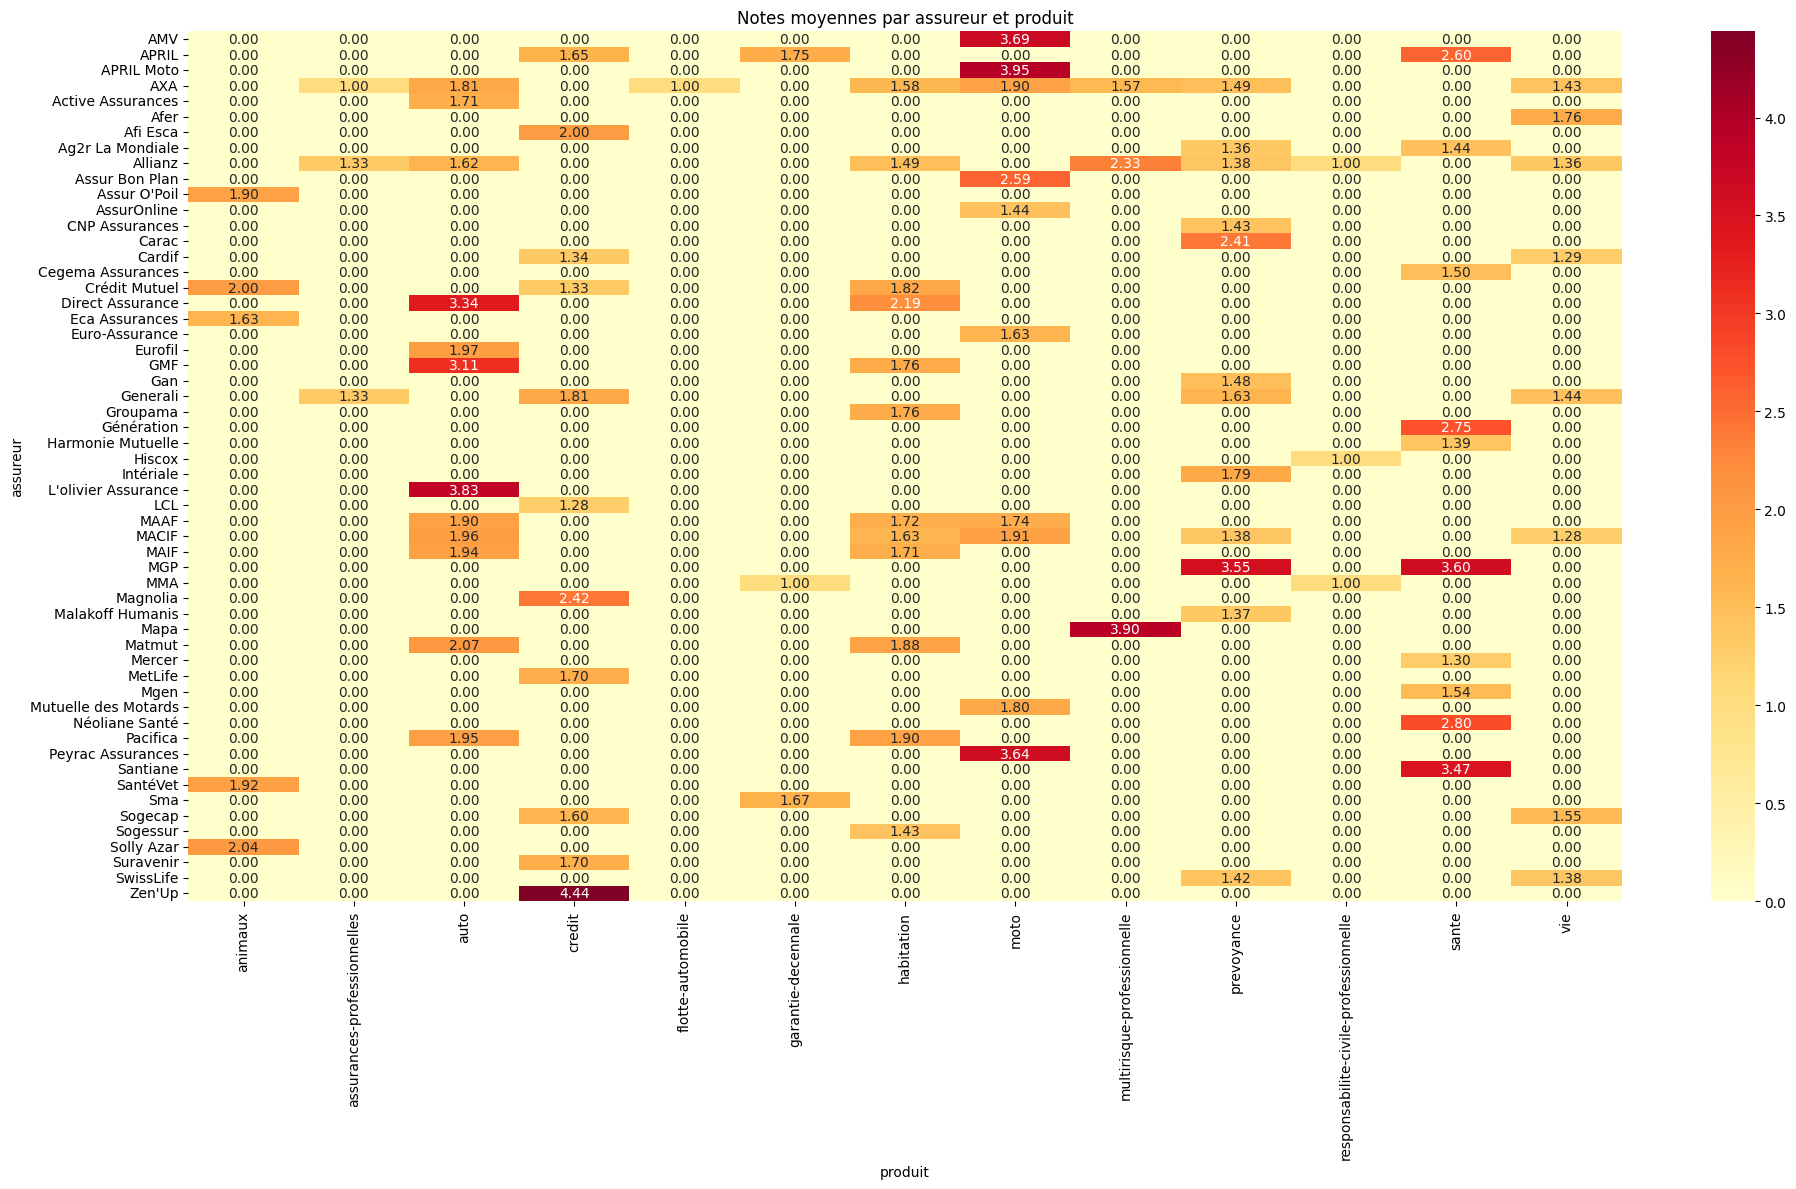

In [ ]:
# Création du tableau croisé dynamique
tableau_notes = pd.pivot_table(df_train,
                             values='note',
                             index='assureur',
                             columns='produit',
                             aggfunc='mean',
                             fill_value=0)

# Arrondir les valeurs à 2 décimales
tableau_notes = tableau_notes.round(2)

# Statistiques supplémentaires
print("\nStatistiques globales :")
print(f"Note moyenne globale : {df_train['note'].mean():.2f}")
print(f"Nombre total d'avis : {len(df_train)}")

# Nombre d'avis par assureur
print("\nNombre d'avis par assureur :")
print(df_train['assureur'].value_counts())

# Nombre d'avis par produit
print("\nNombre d'avis par produit :")
print(df_train['produit'].value_counts())

# Visualisation avec heatmap
plt.figure(figsize=(20, 12))
sns.heatmap(tableau_notes, annot=True, cmap='YlOrRd', fmt='.2f')
plt.title('Notes moyennes par assureur et produit')
plt.tight_layout()
plt.show()


Création des visualisations...


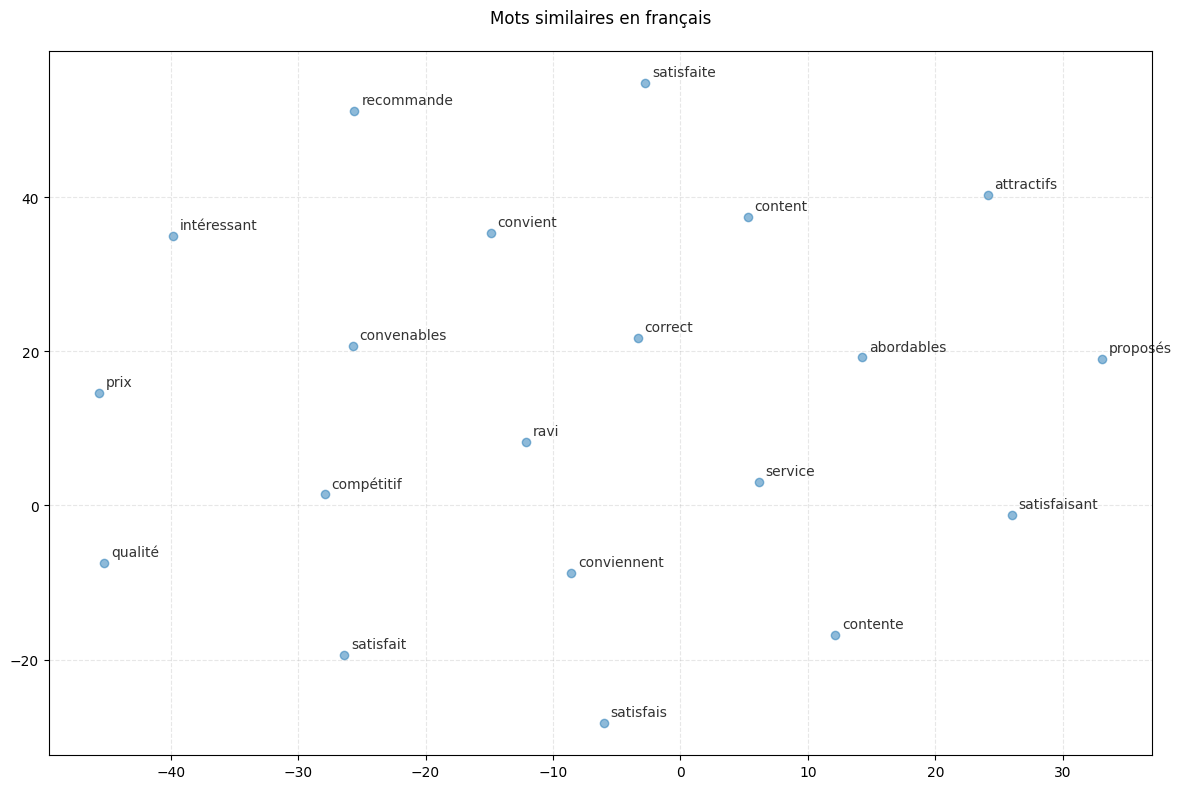

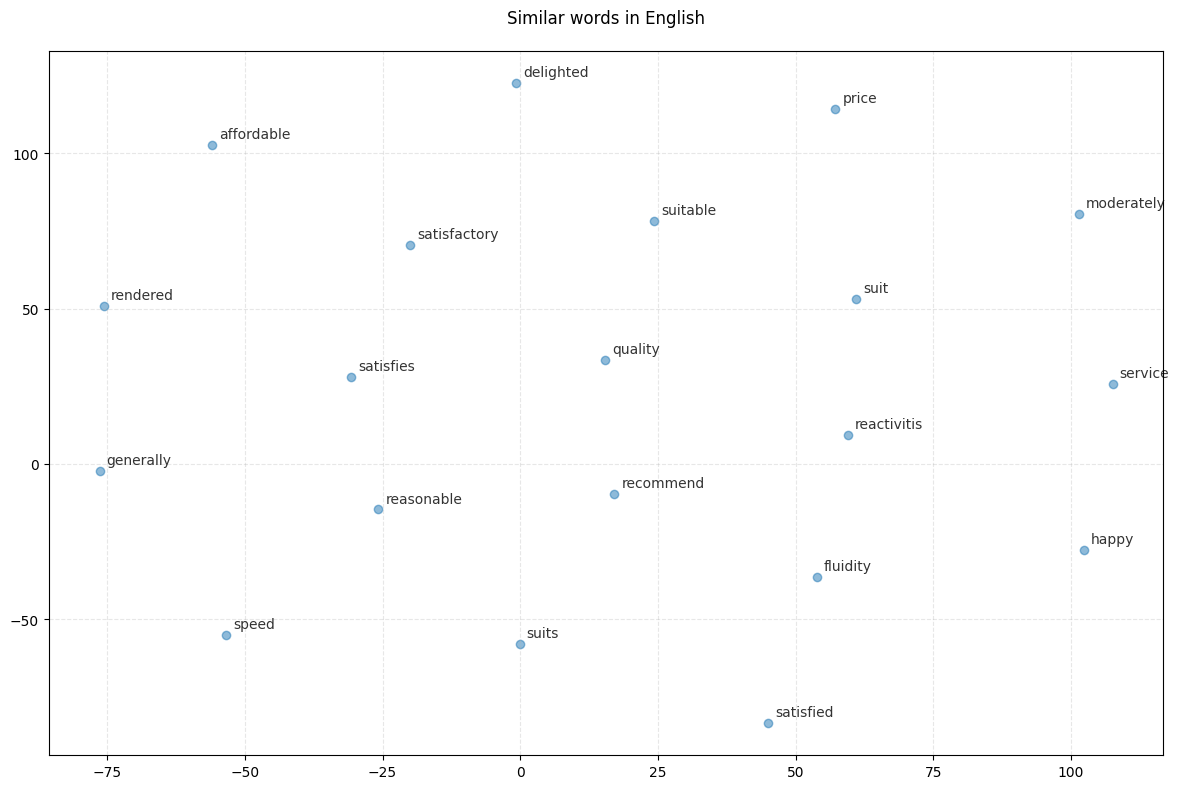

Création des visualisations...

Visualisation créée dans : /content/logs/embeddings_french_20250116-231103

Pour visualiser, exécutez cette commande dans votre terminal :
tensorboard --logdir="/content/logs/embeddings_french_20250116-231103"

Visualisation créée dans : /content/logs/embeddings_english_20250116-231105

Pour visualiser, exécutez cette commande dans votre terminal :
tensorboard --logdir="/content/logs/embeddings_english_20250116-231105"

=== Recherche sémantique ===

Recherche en français:

Résultats pour 'service client':
- déplorable: 0.7918
- inexistant: 0.7762
- médiocre: 0.7416
- clientèle: 0.7391
- joignable: 0.7358

Résultats pour 'prix élevé':
- franchises: 0.8877
- marché: 0.8840
- élevées: 0.8673
- tarif: 0.8601
- légèrement: 0.8330

Résultats pour 'bonne qualité':
- excellent: 0.8585
- satisfaisant: 0.8402
- excellente: 0.8323
- top: 0.8265
- qualite: 0.8182

Search in English:

Results for 'customer service':
- deplorable: 0.7984
- sales: 0.7579
- relations: 0

In [ ]:
# Définition des mots exemples pour chaque langue
example_words_fr = ['satisfait', 'service', 'prix', 'qualité', 'recommande']
example_words_en = ['satisfied', 'service', 'price', 'quality', 'recommend']

# Préparation des données pour Word2Vec
def prepare_sentences(texts):
    """Prépare les textes pour Word2Vec"""
    return [text.split() for text in texts if not pd.isna(text)]

# Entraînement des modèles Word2Vec pour chaque langue
sentences_fr = prepare_sentences(df_train['avis_cleaned'])
sentences_en = prepare_sentences(df_train['avis_en_cleaned'])

w2v_fr = Word2Vec(sentences=sentences_fr, vector_size=100, window=5, min_count=2, workers=4)
w2v_en = Word2Vec(sentences=sentences_en, vector_size=100, window=5, min_count=2, workers=4)

def find_similar_words(word, model, n=10):
    """Trouve les mots les plus similaires"""
    try:
        similar_words = model.wv.most_similar(word, topn=n)
        return similar_words
    except KeyError:
        return []

def visualize_words(words, model, title):
    """Visualise les mots dans un espace 2D"""
    # Obtenir les vecteurs des mots
    word_vectors = []
    valid_words = []

    for word in words:
        if word in model.wv:
            word_vectors.append(model.wv[word])
            valid_words.append(word)

    if not word_vectors:
        print(f"Aucun mot valide trouvé pour la visualisation de '{title}'")
        return

    # Conversion en array NumPy
    vectors = np.array(word_vectors)

    # Réduire la dimensionnalité avec t-SNE
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(vectors)-1))
    vectors_2d = tsne.fit_transform(vectors)

    # Créer le plot
    plt.figure(figsize=(12, 8))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.5)

    # Ajouter les labels
    for i, word in enumerate(valid_words):
        plt.annotate(word,
                    (vectors_2d[i, 0], vectors_2d[i, 1]),
                    xytext=(5, 5),
                    textcoords='offset points',
                    fontsize=10,
                    alpha=0.8)

    plt.title(title, fontsize=12, pad=20)
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

# Utilisation de la fonction corrigée
print("\nCréation des visualisations...")

# Pour le français
top_words_fr = [word for word, _ in w2v_fr.wv.most_similar(positive=example_words_fr[0], topn=15)]
visualize_words(example_words_fr + top_words_fr, w2v_fr, "Mots similaires en français")

# Pour l'anglais
top_words_en = [word for word, _ in w2v_en.wv.most_similar(positive=example_words_en[0], topn=15)]
visualize_words(example_words_en + top_words_en, w2v_en, "Similar words in English")

def visualize_with_tensorboard(model, name="word2vec"):
    """
    Visualise les embeddings Word2Vec avec TensorBoard en utilisant PyTorch
    """
    # Création du chemin absolu pour les logs
    log_dir = os.path.join(os.getcwd(), f"logs/embeddings_{name}_{datetime.now().strftime('%Y%m%d-%H%M%S')}")
    os.makedirs(log_dir, exist_ok=True)

    # Initialisation du writer
    writer = SummaryWriter(log_dir)

    # Préparation des données
    vectors = []
    words = []

    # Récupération des mots et vecteurs
    for word in model.wv.key_to_index:
        vectors.append(model.wv[word])
        words.append(word)

    # Conversion en array numpy
    vectors = np.array(vectors)

    # Création du fichier de métadonnées
    metadata_path = os.path.join(log_dir, "metadata.tsv")
    with open(metadata_path, 'w', encoding='utf-8') as f:
        for word in words:
            f.write(f"{word}\n")

    # Ajout des embeddings à TensorBoard
    writer.add_embedding(
        vectors,
        metadata=words,
        tag=f'embeddings_{name}'
    )

    writer.close()

    print(f"\nVisualisation créée dans : {log_dir}")
    print("\nPour visualiser, exécutez cette commande dans votre terminal :")
    print(f"tensorboard --logdir=\"{log_dir}\"")

    return log_dir

# Visualisation des embeddings
print("Création des visualisations...")
log_dir_fr = visualize_with_tensorboard(w2v_fr, "french")
log_dir_en = visualize_with_tensorboard(w2v_en, "english")

# Analyse sémantique
def semantic_search(query, model, n=5):
    """Recherche sémantique dans le modèle"""
    try:
        results = model.wv.most_similar(positive=query.split(), topn=n)
        return results
    except KeyError:
        return []

# Exemples de recherche sémantique
print("\n=== Recherche sémantique ===")
queries_fr = ['service client', 'prix élevé', 'bonne qualité']
queries_en = ['customer service', 'high price', 'good quality']

print("\nRecherche en français:")
for query in queries_fr:
    results = semantic_search(query, w2v_fr)
    if results:
        print(f"\nRésultats pour '{query}':")
        for word, score in results:
            print(f"- {word}: {score:.4f}")

print("\nSearch in English:")
for query in queries_en:
    results = semantic_search(query, w2v_en)
    if results:
        print(f"\nResults for '{query}':")
        for word, score in results:
            print(f"- {word}: {score:.4f}")

# Statistiques sur les modèles
print("\n=== Statistiques des modèles ===")
print(f"Taille du vocabulaire français: {len(w2v_fr.wv.key_to_index)}")
print(f"Taille du vocabulaire anglais: {len(w2v_en.wv.key_to_index)}")

## Modèle

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 18s 17ms/step - loss: 7.0587 - mae: 1.6879 - mse: 4.3792 - val_loss: 1.7221 - val_mae: 0.7691 - val_mse: 0.9197
Epoch 2/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - loss: 2.1453 - mae: 0.9412 - mse: 1.4623 - val_loss: 1.2534 - val_mae: 0.7117 - val_mse: 0.8184
Epoch 3/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 1.5769 - mae: 0.8424 - mse: 1.1846 - val_loss: 1.0548 - val_mae: 0.6898 - val_mse: 0.7597
Epoch 4/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 1.3128 - mae: 0.7904 - mse: 1.0407 - val_loss: 0.9535 - val_mae: 0.6814 - val_mse: 0.7338
Epoch 5/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 1.1384 - mae: 0.7549 - mse: 0.9326 - val_loss: 0.9415 - val_mae: 0.7050 - val_mse: 0.7718
Epoch 6/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - loss: 1.0691 - mae: 0.7550 - mse: 0.9075 - val_loss: 0.8786 - val_mae: 0.7012 - val_mse: 0.7401
Epoch 7/10
565/565 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 0.9802 - mae: 0.7318 - mse:

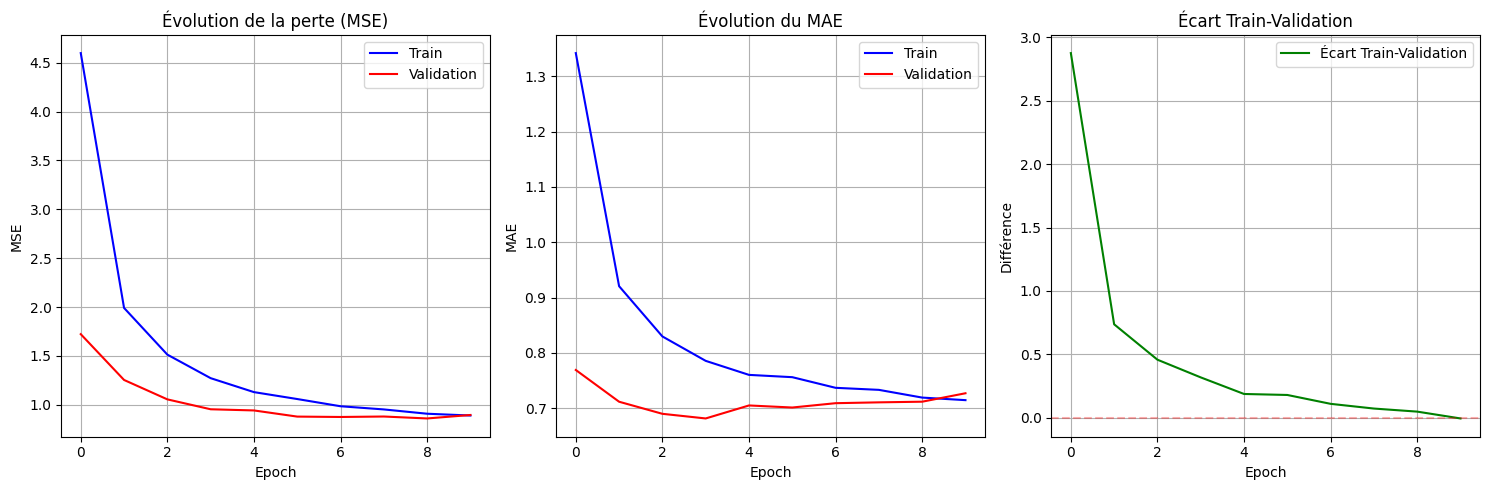


Analyse du surapprentissage :
Métriques finales :
Loss (Train) : 0.8895
Loss (Validation) : 0.8951
MAE (Train) : 0.7145
MAE (Validation) : 0.7270

Pourcentage de surapprentissage : 0.62%
Meilleure epoch : 9
Nombre total d'epochs effectuées : 10


In [ ]:
# ====================================
# PRÉPARATION DES DONNÉES
# ====================================

# Encoder les variables catégorielles
label_encoder_assureur = LabelEncoder()
label_encoder_produit = LabelEncoder()

# Encoder assureur et produit sur tout df_train
assureur_encoded = label_encoder_assureur.fit_transform(df_train['assureur'])
produit_encoded = label_encoder_produit.fit_transform(df_train['produit'])

# Ajouter l'encodage de la langue
lang_encoded = np.array([1 if pd.isna(row['avis_en_cleaned']) else 0 for _, row in df_train.iterrows()])

# Préparation du texte
MAX_WORDS = 13000
MAX_LENGTH = 100

# Tokenization du texte
tokenizer = Tokenizer(num_words=MAX_WORDS)
# Utiliser les deux colonnes pour l'entraînement du tokenizer
texts_for_tokenizer = []
for idx, row in df_train.iterrows():
    if pd.isna(row['avis_en_cleaned']):
        texts_for_tokenizer.append(row['avis_cleaned'])
    else:
        texts_for_tokenizer.append(row['avis_en_cleaned'])

tokenizer.fit_on_texts(texts_for_tokenizer)

X_text = []
languages = []
for idx, row in df_train.iterrows():
    if pd.isna(row['avis_en_cleaned']):
        text = row['avis_cleaned']
        languages.append(1)  # français
    else:
        text = row['avis_en_cleaned']
        languages.append(0)  # anglais
    X_text.append(text)

X_text = tokenizer.texts_to_sequences(X_text)
X_text = pad_sequences(X_text, maxlen=MAX_LENGTH)
languages = np.array(languages)

# ====================================
# CRÉATION DU MODÈLE
# ====================================

# Branche texte
text_input = Input(shape=(MAX_LENGTH,))
text_embedding = Embedding(MAX_WORDS, 64, input_length=MAX_LENGTH)(text_input)
text_lstm1 = LSTM(64, return_sequences=True, kernel_regularizer=l2(0.02))(text_embedding)
text_dropout1 = Dropout(0.4)(text_lstm1)
text_lstm2 = LSTM(32, kernel_regularizer=l2(0.02))(text_dropout1)
text_features = Dropout(0.3)(text_lstm2)

# Branche assureur
assureur_input = Input(shape=(1,))
assureur_embedding = Embedding(len(label_encoder_assureur.classes_), 4)(assureur_input)
assureur_features = tf.keras.layers.Flatten()(assureur_embedding)

# Branche produit
produit_input = Input(shape=(1,))
produit_embedding = Embedding(len(label_encoder_produit.classes_), 2)(produit_input)
produit_features = tf.keras.layers.Flatten()(produit_embedding)

# Nouvelle branche pour la langue
lang_input = Input(shape=(1,))
lang_features = Dense(2, activation='relu')(lang_input)

# Fusion des features avec la langue
concat = Concatenate()([text_features, assureur_features, produit_features, lang_features])

# Reste du modèle (inchangé)
dense1 = Dense(32, activation='relu', kernel_regularizer=l2(0.02))(concat)
dropout1 = Dropout(0.3)(dense1)
dense2 = Dense(16, activation='relu', kernel_regularizer=l2(0.02))(dropout1)
dropout2 = Dropout(0.2)(dense2)
output = Dense(1, activation='linear')(dropout2)

# Création du modèle avec la nouvelle entrée
model = Model(inputs=[text_input, assureur_input, produit_input, lang_input], outputs=output)

# Compilation
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='mse',
    metrics=['mae', 'mse']
)

# Early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True,
    mode='min',
    min_delta=0.001
)

# Entraînement
history = model.fit(
    [X_text, assureur_encoded, produit_encoded, languages],
    df_train['note'],
    epochs=10,
    batch_size=32,
    validation_split=0.25,
    callbacks=[early_stopping],
    verbose=1
)

# Sauvegarde du modèle et des encodeurs
model_artifacts = {
    'model': model,
    'tokenizer': tokenizer,
    'max_length': MAX_LENGTH,
    'label_encoder_assureur': label_encoder_assureur,
    'label_encoder_produit': label_encoder_produit,
    'lang_feature': True  # Ajout d'un indicateur pour la feature langue
}

# ====================================
# VISUALISATION DE L'APPRENTISSAGE ET DU SURAPPRENTISSAGE
# ====================================
plt.figure(figsize=(15, 5))

# 1. Évolution de la perte (MSE)
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='Train', color='blue')
plt.plot(history.history['val_loss'], label='Validation', color='red')
plt.title('Évolution de la perte (MSE)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)

# 2. Évolution du MAE
plt.subplot(1, 3, 2)
plt.plot(history.history['mae'], label='Train', color='blue')
plt.plot(history.history['val_mae'], label='Validation', color='red')
plt.title('Évolution du MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

# 3. Écart Train/Validation
plt.subplot(1, 3, 3)
train_val_diff = np.array(history.history['loss']) - np.array(history.history['val_loss'])
plt.plot(train_val_diff, label='Écart Train-Validation', color='green')
plt.axhline(y=0, color='r', linestyle='--', alpha=0.3)
plt.title('Écart Train-Validation')
plt.xlabel('Epoch')
plt.ylabel('Différence')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Afficher les métriques finales et l'analyse du surapprentissage
print("\nAnalyse du surapprentissage :")
print("Métriques finales :")
print(f"Loss (Train) : {history.history['loss'][-1]:.4f}")
print(f"Loss (Validation) : {history.history['val_loss'][-1]:.4f}")
print(f"MAE (Train) : {history.history['mae'][-1]:.4f}")
print(f"MAE (Validation) : {history.history['val_mae'][-1]:.4f}")

# Calculer le pourcentage de surapprentissage
overfit_percentage = ((history.history['loss'][-1] - history.history['val_loss'][-1]) / history.history['val_loss'][-1]) * 100
print(f"\nPourcentage de surapprentissage : {abs(overfit_percentage):.2f}%")

# Analyse de la convergence
best_epoch = np.argmin(history.history['val_loss']) + 1
print(f"Meilleure epoch : {best_epoch}")
print(f"Nombre total d'epochs effectuées : {len(history.history['loss'])}")

with open('model_notes.pkl', 'wb') as file:
    pickle.dump(model_artifacts, file)

## Application

In [ ]:
# Pour lancer l'application la première fois pas besoin
# Si des modifications effectuées sur app.py, obligation de lancer ce code pour sauvegarder les changements

!killall streamlit
!killall ngrok
time.sleep(2)

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
from langdetect import detect
import pickle
from transformers import pipeline, AutoModelForSequenceClassification, AutoTokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import math
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import torch

# Chargement des modèles et données
@st.cache_resource
def load_explanation_model():
    return pipeline("text-generation", model="facebook/bart-large-cnn")

@st.cache_resource
def load_qa_model():
    return pipeline(
        "question-answering",
        model="deepset/roberta-base-squad2",
        tokenizer="deepset/roberta-base-squad2"
    )

@st.cache_resource
def load_retrieval_model():
    return SentenceTransformer('all-MiniLM-L6-v2')

@st.cache_data
def load_data():
    assureurs = pd.read_excel('modalites_assureurs.xlsx')
    produits = pd.read_excel('modalites_produits.xlsx')
    kb = pd.read_excel('df_train.xlsx')
    return assureurs, produits, kb

@st.cache_resource
def load_model():
    with open('model_notes.pkl', 'rb') as file:
        model_artifacts = pickle.load(file)
    return model_artifacts

@st.cache_resource
def load_analysis_model():
    return pipeline(
        "text2text-generation",
        model="google/flan-t5-large",
        max_length=150,
        min_length=50
    )

def prepare_text_for_prediction(text, lang='fr'):
    """
    Prépare le texte pour la prédiction en fonction de la langue
    """
    model_artifacts = load_model()
    tokenizer = model_artifacts['tokenizer']
    max_length = model_artifacts['max_length']

    # Tokenization et padding
    sequences = tokenizer.texts_to_sequences([text])
    padded_sequences = pad_sequences(sequences, maxlen=max_length)

    # Encodage de la langue (1 pour français, 0 pour anglais)
    lang_feature = np.array([1 if lang == 'fr' else 0]).reshape(-1, 1)

    return padded_sequences, lang_feature

def get_explanation(prediction_value, category, avis, similar_reviews, lang='fr', assureur=None, produit=None, kb=None):
    explanation_model = load_explanation_model()

    # Fonction pour extraire les mots clés d'un texte
    def extract_keywords(text):
        # Conversion en minuscules et suppression de la ponctuation
        text = text.lower()
        text = ''.join(c for c in text if c.isalnum() or c.isspace())
        # Création d'une liste de mots
        words = text.split()
        # Filtrage des mots courts (moins de 3 caractères)
        return [w for w in words if len(w) >= 3]

    # Récupération des avis similaires par assureur, produit et note
    if kb is not None and assureur and produit:
        similar_avis = kb[
            (kb['assureur'] == assureur) &
            (kb['produit'] == produit) &
            (kb['note'] == prediction_value)
        ]['avis' if lang == 'fr' else 'avis_en'].tolist()

        # Analyse des mots fréquents dans les avis similaires
        all_words = []
        for similar_avis in similar_avis:
            all_words.extend(extract_keywords(similar_avis))

        # Comptage des occurrences
        from collections import Counter
        word_counts = Counter(all_words)

        # Identification des mots de l'avis actuel qui sont fréquents
        current_words = extract_keywords(avis)
        matching_words = [word for word in current_words if word_counts[word] > 10]

        # Préparation du texte sur les mots fréquents
        if matching_words:
            if lang == 'fr':
                frequent_words_text = f"Les éléments '{', '.join(matching_words)}' de votre avis sont fréquemment mentionnés (plus de 10 fois) dans les avis {assureur} pour {produit} avec une note de {prediction_value}/5."
            else:
                frequent_words_text = f"The elements '{', '.join(matching_words)}' from your review are frequently mentioned (plus de 10 fois) in {assureur} reviews for {produit} with a rating of {prediction_value}/5."
        else:
            if lang == 'fr':
                frequent_words_text = f"Votre avis apporte un point de vue unique pour {assureur} en {produit}."
            else:
                frequent_words_text = f"Your review brings a unique perspective for {assureur} in {produit}."
    else:
        frequent_words_text = ""

    # Création du prompt
    if lang == 'fr':
        prompt = f"""Analyse de cet avis qui a reçu une note de {prediction_value}/5 et est classé dans la catégorie '{category}'.

Avis : {avis}

{frequent_words_text}

"""
    else:
        prompt = f"""Analyze of this review that received a rating of {prediction_value}/5 and is classified as '{category}'.

Review: {avis}

{frequent_words_text}

"""

    explanation = explanation_model(
        prompt,
        max_length=150,
        min_length=50,
        do_sample=True,
        temperature=0.7
    )[0]['generated_text']

    return explanation

def retrieve_similar_reviews(avis, kb, top_k=3, lang='fr'):
    retrieval_model = load_retrieval_model()
    avis_column = 'avis' if lang == 'fr' else 'avis_en'

    query_embedding = retrieval_model.encode([avis])
    kb_embeddings = retrieval_model.encode(kb[avis_column].tolist())

    similarities = cosine_similarity(query_embedding, kb_embeddings)[0]
    top_indices = similarities.argsort()[-top_k:][::-1]

    return kb.iloc[top_indices]

def answer_question(question, context, similar_reviews, lang='fr'):
    analysis_model = load_analysis_model()

    if lang == 'fr':
        formatted_context = f"""
        Avis client : {context}
        Question : {question}

        Génère une réponse directe et factuelle basée uniquement sur l'avis, en utilisant naturellement les mots de la question.
        """
    else:
        formatted_context = f"""
        Customer review: {context}
        Question: {question}

        Generate a direct and factual answer based only on the review, naturally using the words from the question.
        """

    try:
        response = analysis_model(
            formatted_context,
            max_length=150,
            min_length=30,
            do_sample=False,
            temperature=0.1,
            num_beams=1,
            repetition_penalty=2.5
        )[0]['generated_text']

        return response.strip()

    except Exception as e:
        return f"Erreur lors de l'analyse : {str(e)}" if lang == 'fr' else f"Error during analysis: {str(e)}"

def main():
    st.title("Prédiction et Analyse d'Avis d'Assurance")

    # Initialisation de la session state
    if 'prediction_done' not in st.session_state:
        st.session_state.prediction_done = False
    if 'similar_reviews' not in st.session_state:
        st.session_state.similar_reviews = None
    if 'avis_text' not in st.session_state:
        st.session_state.avis_text = None
    if 'lang' not in st.session_state:
        st.session_state.lang = None
    if 'prediction_value' not in st.session_state:
        st.session_state.prediction_value = None
    if 'category' not in st.session_state:
        st.session_state.category = None

    # Chargement des données
    assureurs, produits, kb = load_data()
    model_artifacts = load_model()
    model = model_artifacts['model']
    label_encoder_assureur = model_artifacts['label_encoder_assureur']
    label_encoder_produit = model_artifacts['label_encoder_produit']

    # Interface utilisateur
    col1, col2 = st.columns(2)
    with col1:
        assureur = st.selectbox("Choisissez l'assureur", options=assureurs['assureur'].tolist())
    with col2:
        produit = st.selectbox("Choisissez le produit", options=produits['produit'].tolist())

    avis = st.text_area("Écrivez votre avis ici", height=150)

    if st.button("Analyser l'avis"):
        if avis:
            try:
                # Détection de la langue
                lang = detect(avis)
                st.session_state.lang = lang

                if lang in ['fr', 'en']:
                    # Prédiction de la note avec la nouvelle feature langue
                    text_input, lang_feature = prepare_text_for_prediction(avis, lang)
                    assureur_encoded = label_encoder_assureur.transform([assureur])
                    produit_encoded = label_encoder_produit.transform([produit])

                    prediction = model.predict([
                        text_input,
                        np.array(assureur_encoded, dtype=np.int32).reshape(-1, 1),
                        np.array(produit_encoded, dtype=np.int32).reshape(-1, 1),
                        lang_feature
                    ])[0]

                    prediction_value = int(round(float(prediction)))
                    if prediction_value % 1 >= 0.5:
                        prediction_value = int(math.ceil(prediction_value))
                    else:
                        prediction_value = int(math.floor(prediction_value))

                    st.session_state.prediction_value = prediction_value

                    # Affichage de la note prédite
                    if prediction_value <= 2:
                        st.error(f"Note prédite : {prediction_value} étoile{'' if prediction_value == 1 else 's'}")
                    elif prediction_value == 3:
                        st.warning(f"Note prédite : {prediction_value} étoiles")
                    else:
                        st.success(f"Note prédite : {prediction_value} étoiles")

                    # Classification de la catégorie
                    classifier = pipeline("zero-shot-classification", model="facebook/bart-large-mnli")
                    categories = ["Prix", "Couverture d'assurance", "Inscription", "Service client",
                                "Traitement des réclamations", "Annulation", "Autre"] if lang == 'fr' else \
                               ["Pricing", "Coverage", "Enrollment", "Customer Service",
                                "Claims Processing", "Cancellation", "Other"]

                    result = classifier(avis, categories)
                    category = result['labels'][0]
                    st.session_state.category = category
                    st.info(f"Catégorie principale : {category}")

                    # Recherche d'avis similaires
                    similar_reviews = retrieve_similar_reviews(avis, kb, lang=lang)
                    st.session_state.similar_reviews = similar_reviews
                    st.session_state.avis_text = avis
                    st.session_state.prediction_done = True

                    # Explication de la prédiction
                    with st.expander("Voir l'explication détaillée"):
                        explanation = get_explanation(
                            prediction_value,
                            category,
                            avis,
                            similar_reviews,
                            lang=lang,
                            assureur=assureur,
                            produit=produit,
                            kb=kb
                        )
                        st.write(explanation)

                    # Affichage des avis similaires
                    with st.expander("Voir les avis similaires"):
                        avis_column = 'avis' if lang == 'fr' else 'avis_en'
                        for idx, review in similar_reviews.iterrows():
                            st.write(f"Note : {review['note']}/5")
                            st.write(f"Avis : {review[avis_column]}")
                            st.write("---")

                else:
                    st.error("Désolé, seuls les avis en français ou en anglais sont acceptés.")

            except Exception as e:
                st.error(f"Une erreur s'est produite : {str(e)}")
                st.error(f"Type de l'erreur : {type(e)}")
        else:
            st.warning("Veuillez entrer un avis avant de faire une prédiction.")

    # Interface Q&A (en dehors du if st.button)
    if st.session_state.prediction_done:
        with st.expander("Poser une question sur l'avis"):
            with st.form(key='qa_form'):
                question = st.text_input("Votre question :")
                submit_button = st.form_submit_button(label='Poser la question')

                if submit_button and question:
                    with st.spinner('Analyse en cours...'):
                        try:
                            answer = answer_question(
                                question,
                                st.session_state.avis_text,
                                st.session_state.similar_reviews,
                                st.session_state.lang
                            )
                            if answer:
                                st.markdown("**Réponse :**")
                                st.markdown(answer)
                            else:
                                st.error("La réponse générée est vide")
                        except Exception as e:
                            st.error(f"Erreur lors de l'analyse : {str(e)}")

if __name__ == "__main__":
    main()

Overwriting app.py


In [ ]:
# Redémarrer Streamlit et créer un nouveau tunnel
!streamlit run app.py &>/dev/null &
time.sleep(5)  # Attendre que Streamlit démarre

!ngrok authtoken 2rZo7eOnQWBSIYMfrDKssP40u3H_7yQDfJdz69AoYTe9qPAc9

# Créer un nouveau tunnel
ngrok_tunnel = ngrok.connect(addr="8501", proto="http", bind_tls=True)
print(f"L'application est accessible à cette URL : {ngrok_tunnel.public_url}")

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml
L'application est accessible à cette URL : https://a24b-34-168-254-237.ngrok-free.app
